## Доступные GPU

In [1]:
import csv
import io
import subprocess

fields = ["index", "name", "memory.total", "memory.used", "utilization.gpu", "temperature.gpu"]

result = subprocess.run(
    ["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader"],
    capture_output=True,
    text=True,
    check=True,
    timeout=15,
)

for row in csv.reader(io.StringIO(result.stdout), skipinitialspace=True):
    gpu = dict(zip(fields, row))

    print(f"GPU {gpu['index']}: {gpu['name']}")
    print(f"  Память:     {gpu['memory.used']} / {gpu['memory.total']}")
    print(f"  Загрузка:   {gpu['utilization.gpu']}")
    print(f"  Температура: {gpu['temperature.gpu']} °C")
    print()

GPU 0: NVIDIA RTX A4000
  Память:     8036 MiB / 16376 MiB
  Загрузка:   23 %
  Температура: 50 °C

GPU 1: NVIDIA RTX A4000
  Память:     8829 MiB / 16376 MiB
  Загрузка:   100 %
  Температура: 72 °C

GPU 2: NVIDIA RTX A4000
  Память:     6264 MiB / 16376 MiB
  Загрузка:   15 %
  Температура: 54 °C

GPU 3: NVIDIA RTX A4000
  Память:     6824 MiB / 16376 MiB
  Загрузка:   36 %
  Температура: 51 °C

GPU 4: NVIDIA RTX A4000
  Память:     6711 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 42 °C

GPU 5: NVIDIA RTX A4000
  Память:     14425 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 26 °C

GPU 6: NVIDIA RTX A4000
  Память:     8184 MiB / 16376 MiB
  Загрузка:   23 %
  Температура: 42 °C



## Импорты и параметры

In [2]:
%matplotlib inline

import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch

import cute_rmsnorm
import triton_rmsnorm
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

device = torch.device("cuda:6")
torch.cuda.set_device(device)
major, minor = torch.cuda.get_device_capability(device)
os.environ["TORCH_CUDA_ARCH_LIST"] = f"{major}.{minor}+PTX"

M, N = 4096, 4096
EPS = cute_rmsnorm.EPS
DTYPE = torch.float32
SEED = 42
RTOL = 1e-5
ATOL = 1e-6


def make_rmsnorm_inputs(rows, cols):
    return make_inputs(
        (rows, cols), (rows, cols), (cols,), dtype=DTYPE, seed=SEED, device=device
    )


def residual_rms_norm(x, residual, weight):
    y = x + residual
    return torch.nn.functional.rms_norm(y, (y.shape[-1],), weight, eps=EPS)


def residual_rms_norm_ops(x, residual, weight):
    y = x + residual
    inv_rms = torch.rsqrt(y.square().mean(dim=-1, keepdim=True) + EPS)
    return y * inv_rms * weight

## Реализации

In [3]:
# Добавь имя готового ядра, чтобы включить его в проверку, замер и экспорт.
ENABLED_BACKENDS = ("torch", "torch_compile", "cute")

runners = {
    "torch": make_runner("torch", residual_rms_norm),
    "torch_compile": make_runner("torch_compile", residual_rms_norm_ops),
    "triton": make_runner(
        "triton", triton_rmsnorm.residual_rms_norm_kernel,
        extra_args=lambda x, residual, weight, out: (x.stride(0), x.shape[1], EPS),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "cute": make_runner("cute", cute_rmsnorm.rms_norm(autotune=False)),
    "cuda": make_runner("cuda", "cuda_rmsnorm.cu", entry="rms_norm"),
}
implementations = {name: runners[name] for name in ENABLED_BACKENDS}

## Проверка корректности


In [4]:
for rows, cols in [(1, 1), (3, 7), (5, 255), (2, 256), (3, 257), (7, 1000),
                   (4, 4096), (3, 8196), (M, N)]:
    inputs = make_rmsnorm_inputs(rows, cols)
    expected = residual_rms_norm(*inputs)
    for name, fn in implementations.items():
        torch.testing.assert_close(
            fn(*inputs), expected, rtol=RTOL, atol=ATOL,
            msg=lambda error: f"{name}, {rows}x{cols}\n{error}",
        )
print("OK")

/home/babanovil/ysda-dsl/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


OK


## Бенчмарк

         torch: 1490.944 us (p20-p80: 1029.939-2136.883) | 0.056264 TFLOP/s | 135.04 GB/s | 0.43x
 torch_compile: 644.096 us (p20-p80: 641.677-1632.256) | 0.130238 TFLOP/s | 312.60 GB/s | 1.00x
          cute: 517.120 us (p20-p80: 515.174-1466.573) | 0.162218 TFLOP/s | 389.35 GB/s | 1.25x


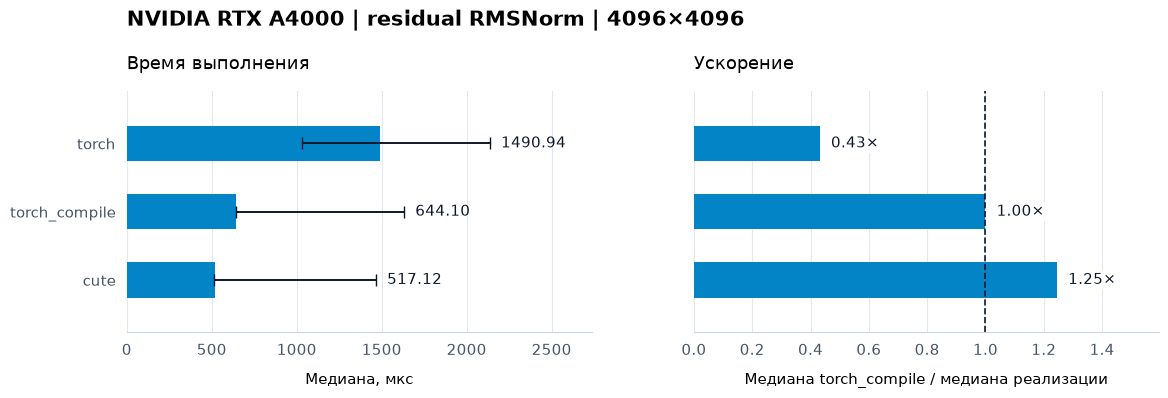

In [5]:
inputs = make_rmsnorm_inputs(M, N)
# На элемент: residual add, квадрат, сложение для суммы и два умножения.
results = run_benchmark(implementations, inputs, reference=residual_rms_norm, flops=5 * M * N)
plot_benchmark(
    results, baseline="torch_compile",
    title=f"{torch.cuda.get_device_name(device)} | residual RMSNorm | {M}×{N}",
)
plt.show()

## PTX и SASS

In [6]:
for name, fn in implementations.items():
    assembly = fn.asm()
    dump_asm(assembly, Path("asm") / name)
    print(name, list(assembly))

torch []
torch_compile ['triton_poi_fused_add_mean_mul_pow_rsqrt_0', 'triton_red_fused_add_mean_mul_pow_rsqrt_0']
cute ['rms_norm']
